# Baseline 2 — Multi-task ResNet-50 for Unseen Plant Disease Identification
**COS30082 ML Project · Group 8 · DPD-Small**

One shared ResNet-50 backbone with two heads, one predicting the **crop** (55 classes) and one the **disease** (175 classes). Unseen classes are new *crop + disease pairings*, so we never classify pairs directly. Instead every one of the 333 valid pairs is scored as

$$\text{score}(c, d) = \log P(\text{crop}=c) + \log P(\text{disease}=d) + b\cdot\mathbb{1}[(c,d)\ \text{not trained on}]$$

which lets the model predict pairs it has never seen. The calibration bias $b$ offsets the model's natural preference for seen pairs.

### How to run (two passes)
1. **`run_mode='dev'`**: holds out 15 seen pairs as *pseudo-unseen* validation. It picks the best epoch and the bias $b$ **without touching the test set**.
2. **`run_mode='final'`**: retrains on all 8 000 training images for the chosen number of epochs, then reports Top-1/Top-5, harmonic mean and confusion matrices on the real test sets using the dev bias.

**Data:** the team archive `MyDrive/COS30082/DPD_Small.7z`, the same one the ViT notebook uses. If you don't have it, ask for the shared folder or download DPD-Small from the link in the assignment PDF.

Checkpoints save to Drive every epoch, so after a Colab disconnect just *Run all* again and it resumes.

## 1. Environment setup

In [1]:
import os, sys, json, time, math, random, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=True)

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = DEVICE == 'cuda'   # mixed precision only on GPU
print('device:', DEVICE, torch.cuda.get_device_name(0) if AMP else '(no GPU: Runtime > Change runtime type > T4)')

Mounted at /content/drive
device: cuda Tesla T4


## 2. Configuration
Everything you might change lives here. Run the notebook once with `run_mode='dev'`, then once with `run_mode='final'`.

In [2]:
CFG = dict(
    run_mode='dev',          # 'dev' = tune on pseudo-unseen split | 'final' = train on all 8000, evaluate on test
    drive_root='/content/drive/MyDrive/COS30082',   # team Drive folder holding DPD_Small.7z (as in the ViT notebook)
    archive_name='DPD_Small.7z',
    data_root='/content/data',   # where the archive is extracted (as in the ViT notebook)
    local_root='/content',   # fast local disk for the resized image cache
    cache_size=320,          # shorter image side after a one-off resize (originals are up to 4000px)
    backbone='resnet50.a1_in1k',
    pretrained=True,
    img_size=224,
    batch_size=64,
    epochs=25,               # dev: max epochs (best one is kept) | final: replaced by the dev best epoch
    freeze_epochs=1,         # train only the two heads first, then unfreeze the backbone
    warmup_epochs=1,
    lr_backbone=1e-4,
    lr_heads=1e-3,
    weight_decay=0.05,
    label_smoothing=0.1,
    lambda_disease=1.0,      # L = CE_crop + lambda * CE_disease
    dropout=0.2,
    num_holdout_pairs=15,    # dev only: seen pairs held out as pseudo-unseen validation
    val_frac=0.1,            # dev only: share of each remaining pair kept for seen validation
    num_workers=2,
    seed=42,
)
# Local CPU smoke tests override settings through an env var (unused on Colab)
if os.environ.get('DPD_CFG'):
    CFG.update(json.loads(os.environ['DPD_CFG']))
assert CFG['run_mode'] in ('dev', 'final')

CACHE_DIR = os.path.join(CFG['local_root'], f"dpd_small_{CFG['cache_size']}")
CACHE_ZIP = os.path.join(CFG['drive_root'], 'cache', f"dpd_small_{CFG['cache_size']}.zip")
OUT_ROOT = os.path.join(CFG['drive_root'], 'outputs', 'baseline2_multitask_resnet50')
OUT_DIR = os.path.join(OUT_ROOT, CFG['run_mode'])
DEV_SUMMARY = os.path.join(OUT_ROOT, 'dev', 'summary.json')
os.makedirs(OUT_DIR, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG['seed'])
print(json.dumps(CFG, indent=2))

{
  "run_mode": "dev",
  "drive_root": "/content/drive/MyDrive/COS30082",
  "archive_name": "DPD_Small.7z",
  "data_root": "/content/data",
  "local_root": "/content",
  "cache_size": 320,
  "backbone": "resnet50.a1_in1k",
  "pretrained": true,
  "img_size": 224,
  "batch_size": 64,
  "epochs": 25,
  "freeze_epochs": 1,
  "warmup_epochs": 1,
  "lr_backbone": 0.0001,
  "lr_heads": 0.001,
  "weight_decay": 0.05,
  "label_smoothing": 0.1,
  "lambda_disease": 1.0,
  "dropout": 0.2,
  "num_holdout_pairs": 15,
  "val_frac": 0.1,
  "num_workers": 2,
  "seed": 42
}


## 3. Get the data onto Colab's local disk
The team keeps DPD-Small as one archive, `MyDrive/COS30082/DPD_Small.7z` (about 3.4 GB). The first time, we copy it to local disk and extract it, the same way the ViT notebook does. Originals are up to 4000px, and decoding them every step would make the GPU wait on the CPU. So we also resize every image once so its shorter side is 320px, and save that small copy (images + CSVs) to Drive as a zip. Later sessions just unzip it, which takes about 1 minute.

In [3]:
from concurrent.futures import ThreadPoolExecutor
CSV_NAMES = ['DPD_Small_train.csv', 'DPD_Small_test_seen.csv', 'DPD_Small_test_unseen.csv']
SRC_IMAGES = os.path.join(CFG['data_root'], 'DPD_Small_dataset')
IMAGE_DIR = os.path.join(CACHE_DIR, 'DPD_Small_dataset')

def extract_archive():
    if os.path.exists(os.path.join(CFG['data_root'], CSV_NAMES[0])):
        return
    archive = os.path.join(CFG['drive_root'], CFG['archive_name'])
    local_archive = os.path.join(CFG['local_root'], CFG['archive_name'])
    print('copying', archive, 'to local disk ...')
    shutil.copy(archive, local_archive)
    print('extracting ...')
    subprocess.run(['7z', 'x', '-y', local_archive, f"-o{CFG['data_root']}"], check=True, stdout=subprocess.DEVNULL)
    os.remove(local_archive)

# Phone photos store their rotation in an EXIF tag. ImageOps.exif_transpose crashes on
# some DPD images whose EXIF is malformed (e.g. a resolution tag saved as text), so we
# read only the orientation tag ourselves and drop the rest of the EXIF.
ORIENTATION_FIX = {2: Image.Transpose.FLIP_LEFT_RIGHT, 3: Image.Transpose.ROTATE_180,
                   4: Image.Transpose.FLIP_TOP_BOTTOM, 5: Image.Transpose.TRANSPOSE,
                   6: Image.Transpose.ROTATE_270, 7: Image.Transpose.TRANSVERSE,
                   8: Image.Transpose.ROTATE_90}

def load_upright(path):
    with Image.open(path) as im:
        try:
            orientation = im.getexif().get(0x0112, 1)
        except Exception:
            orientation = 1
        im = im.convert('RGB')
    if orientation in ORIENTATION_FIX:
        im = im.transpose(ORIENTATION_FIX[orientation])
    im.info = {}
    return im

def resize_one(name):
    dst = os.path.join(IMAGE_DIR, name)
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    im = load_upright(os.path.join(SRC_IMAGES, name))
    scale = CFG['cache_size'] / min(im.size)
    if scale < 1:
        im = im.resize((round(im.width * scale), round(im.height * scale)), Image.BICUBIC)
    im.save(dst, quality=95)

def prepare_data():
    done_flag = os.path.join(CACHE_DIR, '.complete')
    if not os.path.exists(done_flag) and os.path.exists(CACHE_ZIP):
        print('unpacking resized dataset from Drive ...')
        shutil.unpack_archive(CACHE_ZIP, CFG['local_root'])
    if os.path.exists(done_flag):
        print('dataset ready:', CACHE_DIR)
        return
    extract_archive()
    os.makedirs(IMAGE_DIR, exist_ok=True)
    for name in CSV_NAMES:
        shutil.copy(os.path.join(CFG['data_root'], name), CACHE_DIR)
    names = pd.concat([pd.read_csv(os.path.join(CACHE_DIR, n), header=None)[0] for n in CSV_NAMES]).unique()
    print(f'resizing {len(names)} images (one-off) ...')
    with ThreadPoolExecutor(16) as pool:
        for i, _ in enumerate(pool.map(resize_one, names), 1):
            if i % 1000 == 0:
                print(f'  {i}/{len(names)}')
    open(done_flag, 'w').close()
    os.makedirs(os.path.dirname(CACHE_ZIP), exist_ok=True)
    shutil.make_archive(CACHE_ZIP[:-4], 'zip', CFG['local_root'], os.path.basename(CACHE_DIR))
    print('saved resized dataset to Drive:', CACHE_ZIP)

prepare_data()
TRAIN_CSV, TEST_SEEN_CSV, TEST_UNSEEN_CSV = (os.path.join(CACHE_DIR, n) for n in CSV_NAMES)

copying /content/drive/MyDrive/COS30082/DPD_Small.7z to local disk ...
extracting ...
resizing 11448 images (one-off) ...
  1000/11448
  2000/11448
  3000/11448
  4000/11448
  5000/11448
  6000/11448
  7000/11448
  8000/11448
  9000/11448
  10000/11448
  11000/11448
saved resized dataset to Drive: /content/drive/MyDrive/COS30082/cache/dpd_small_320.zip


## 4. Load metadata and build the composition table
CSV columns (no header): `file, crop_id, disease_id, comp_id, crop_name, disease_name, comp_name`.
`COMP_CROP[k]` and `COMP_DIS[k]` give the crop and disease of composition `k`, which is all we need to turn the two heads' outputs into pair scores.

In [4]:
COLS = ['file', 'crop', 'disease', 'comp', 'crop_name', 'disease_name', 'comp_name']

def read_split(path):
    return pd.read_csv(path, header=None, names=COLS)

train_df = read_split(TRAIN_CSV)
test_seen_df = read_split(TEST_SEEN_CSV)
test_unseen_df = read_split(TEST_UNSEEN_CSV)
all_df = pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True)

# Every composition id must map to exactly one (crop, disease) pair
assert (all_df.groupby('comp')[['crop', 'disease']].nunique() == 1).all().all()
comps = (all_df.drop_duplicates('comp').sort_values('comp')
         [['comp', 'crop', 'disease', 'crop_name', 'disease_name', 'comp_name']]
         .reset_index(drop=True))
assert comps['comp'].tolist() == list(range(len(comps))), 'composition ids should run 0..N-1'

NUM_CROPS = int(all_df['crop'].max()) + 1
NUM_DISEASES = int(all_df['disease'].max()) + 1
NUM_COMPS = len(comps)
COMP_CROP = torch.tensor(comps['crop'].values)
COMP_DIS = torch.tensor(comps['disease'].values)
COMP_NAMES = comps['comp_name'].tolist()
CROP_NAMES = all_df.drop_duplicates('crop').set_index('crop')['crop_name'].sort_index().tolist()

TRAIN_COMPS = set(train_df['comp'])
UNSEEN_COMPS = set(test_unseen_df['comp'])
assert not TRAIN_COMPS & UNSEEN_COMPS, 'unseen pairs leaked into training'
print(f'train {len(train_df)} | test-seen {len(test_seen_df)} | test-unseen {len(test_unseen_df)}')
print(f'crops {NUM_CROPS} | diseases {NUM_DISEASES} | compositions {NUM_COMPS} '
      f'(seen {len(TRAIN_COMPS)}, unseen {len(UNSEEN_COMPS)})')

train 8000 | test-seen 2000 | test-unseen 1448
crops 55 | diseases 175 | compositions 333 (seen 323, unseen 10)


## 5. Can the unseen pairs be predicted at all?
A pair can only be predicted if its crop **and** its disease each appear somewhere in training. We also count how many diseases occur on 2+ crops. Those are the diseases where crop-independent symptom features matter, and they set how much room the contrastive method has to improve.

In [5]:
dis_crops = train_df.groupby('disease')['crop'].nunique()
pair_counts = train_df.groupby('comp').size()
print(f'diseases seen on 2+ crops: {(dis_crops >= 2).sum()} / {len(dis_crops)}')
print(f'train images per pair: min {pair_counts.min()} | median {int(pair_counts.median())} | max {pair_counts.max()}')

rows = []
for c in sorted(UNSEEN_COMPS):
    r = comps.loc[c]
    rows.append(dict(
        pair=r.comp_name,
        train_imgs_of_crop=int((train_df['crop'] == r.crop).sum()),
        train_imgs_of_disease=int((train_df['disease'] == r.disease).sum()),
        crops_with_this_disease=int(dis_crops.get(r.disease, 0)),
        test_imgs=int((test_unseen_df['comp'] == c).sum()),
    ))
unseen_table = pd.DataFrame(rows)
display(unseen_table)
blocked = unseen_table[(unseen_table.train_imgs_of_crop == 0) | (unseen_table.train_imgs_of_disease == 0)]
print('WARNING, unpredictable pairs:' if len(blocked) else
      'OK: every unseen pair has its crop and its disease in training', *blocked.pair)

diseases seen on 2+ crops: 42 / 175
train images per pair: min 1 | median 7 | max 544


,pair,train_imgs_of_crop,train_imgs_of_disease,crops_with_this_disease,test_imgs
0,pepper_bell_bacterial_spot,63,188,5,220
1,cherry_aphis_spp,83,7,2,72
2,corn_brown_spot,910,261,8,35
3,cotton_bacterial_blight,56,147,3,125
4,cucumber_downy_mildew,36,69,11,32
5,cucumber_powdery_mildew,36,226,11,37
6,grape_black_rot,167,36,5,271
7,mango_anthracnose,134,51,9,95
8,sugarcane_rust,162,297,12,89
9,tomato_early_blight,1164,102,2,472


OK: every unseen pair has its crop and its disease in training


## 6. Splits — pseudo-unseen validation
The real unseen test can't be used for tuning. In **dev** mode we hold out 15 seen pairs whose crop and disease both still appear in other training pairs, so they mimic the real unseen pairs. This *val-unseen* set picks the epoch and bias. Another 10% of every remaining pair becomes *val-seen*.

In **final** mode we train on all 8 000 images.

`NOVEL_MASK` marks every pair the model did **not** train on. Those pairs receive the bias $b$.

In [6]:
def make_dev_split(df, k, val_frac, seed):
    rng = np.random.RandomState(seed)
    pairs = df.groupby('comp').agg(crop=('crop', 'first'), disease=('disease', 'first'))
    remaining, holdout = pairs.copy(), []
    for c in rng.permutation(pairs.index.values):
        if len(holdout) == k:
            break
        rest = remaining.drop(c)
        # the held-out pair's crop and disease must stay seen elsewhere, as for real unseen pairs
        if (rest['crop'] == pairs.at[c, 'crop']).any() and (rest['disease'] == pairs.at[c, 'disease']).any():
            holdout.append(int(c))
            remaining = rest
    val_unseen = df[df['comp'].isin(holdout)]
    rest_df = df[~df['comp'].isin(holdout)]
    val_idx = []
    for _, g in rest_df.groupby('comp'):
        n_val = int(len(g) * val_frac)   # pairs with < 10 images keep everything for training
        if n_val:
            val_idx += g.sample(n_val, random_state=seed).index.tolist()
    val_seen = rest_df.loc[val_idx]
    fit = rest_df.drop(index=val_idx)
    return (fit.reset_index(drop=True), val_seen.reset_index(drop=True),
            val_unseen.reset_index(drop=True), sorted(holdout))

if CFG['run_mode'] == 'dev':
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = make_dev_split(
        train_df, CFG['num_holdout_pairs'], CFG['val_frac'], CFG['seed'])
    print(f'fit {len(fit_df)} | val-seen {len(val_seen_df)} | val-unseen {len(val_unseen_df)} '
          f'({len(HOLDOUT)} pseudo-unseen pairs)')
    print('pseudo-unseen pairs:', ', '.join(COMP_NAMES[c] for c in HOLDOUT))
else:
    fit_df, val_seen_df, val_unseen_df, HOLDOUT = train_df, None, None, []
    print(f'final mode: training on all {len(fit_df)} images')

FIT_COMPS = sorted(set(fit_df['comp']))
NOVEL_MASK = torch.ones(NUM_COMPS, dtype=torch.bool)
NOVEL_MASK[FIT_COMPS] = False
print(f'pairs trained on: {len(FIT_COMPS)} | novel pairs (get bias b): {int(NOVEL_MASK.sum())}')

fit 6956 | val-seen 638 | val-unseen 406 (15 pseudo-unseen pairs)
pseudo-unseen pairs: apple_healthy, blackgram_powdery_mildew, broccoli_alternaria_leaf_spot, broccoli_ring_spot, cauliflower_bacterial_spot, cauliflower_black_rot, cherry_spot, citrus_black_spot, cucumber_angular_leaf_spot, paddy_bacterial_blight, papaya_curl, plum_aphis_spp, sugarcane_smut, tea_healthy, tomato_mosaic_virus
pairs trained on: 308 | novel pairs (get bias b): 25


## 7. Dataset and augmentation
These are the same ResNet transforms as the team's `Data_augmentation.ipynb`, so every team model sees identical inputs. Colour jitter and rotation help with the lighting and viewpoint changes of field images.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
S = CFG['img_size']

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.8, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class DPDSmallDataset(Dataset):
    # Same labels as the team's DPDSmallDataset, but built from a DataFrame so we can pass our own splits
    def __init__(self, df, img_dir, transform):
        self.files = df['file'].tolist()
        self.labels = df[['crop', 'disease', 'comp']].to_numpy()
        self.img_dir, self.transform = img_dir, transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        image = Image.open(os.path.join(self.img_dir, self.files[i])).convert('RGB')
        crop, disease, comp = self.labels[i]
        return self.transform(image), int(crop), int(disease), int(comp)

def make_loader(df, train):
    ds = DPDSmallDataset(df, IMAGE_DIR, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CFG['batch_size'], shuffle=train, drop_last=train,
                      num_workers=CFG['num_workers'], pin_memory=AMP,
                      persistent_workers=CFG['num_workers'] > 0)

train_loader = make_loader(fit_df, train=True)
if CFG['run_mode'] == 'dev':
    val_seen_loader = make_loader(val_seen_df, train=False)
    val_unseen_loader = make_loader(val_unseen_df, train=False)
print(f'{len(train_loader)} training steps per epoch')

108 training steps per epoch


## 8. Model — shared backbone, two heads
The ImageNet-pretrained ResNet-50 produces one 2048-d feature, and both heads read from it. That shared feature is the point of the multi-task baseline: crop and disease supervision shape the same representation. It's also the source of *entanglement*, because the disease head can lean on crop cues.

In [8]:
class MultiTaskResNet(nn.Module):
    def __init__(self, backbone, n_crops, n_diseases, pretrained, dropout):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)  # -> pooled features
        d = self.backbone.num_features
        self.dropout = nn.Dropout(dropout)
        self.crop_head = nn.Linear(d, n_crops)
        self.disease_head = nn.Linear(d, n_diseases)

    def forward(self, x):
        feat = self.backbone(x)
        h = self.dropout(feat)
        return self.crop_head(h), self.disease_head(h), feat

model = MultiTaskResNet(CFG['backbone'], NUM_CROPS, NUM_DISEASES, CFG['pretrained'], CFG['dropout']).to(DEVICE)
print(f"{CFG['backbone']}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters, "
      f"feature dim {model.backbone.num_features}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50.a1_in1k: 24.0M parameters, feature dim 2048


## 9. Evaluation protocol (shared with the team)
- **Pair scores:** `log P(crop) + log P(disease)` for all 333 pairs, plus bias $b$ on novel pairs.
- **Top-k accuracy** over all 333 pairs (generalised setting: seen and unseen pairs compete).
- **Bias sweep:** each sample flips from a seen to a novel prediction at one specific $b$. Sweeping through those points traces the full seen-vs-unseen accuracy curve. We report the best **harmonic mean** $H = 2SU/(S+U)$ and the **AUC** under the curve.

Every team model should report numbers with these same functions so the comparison is fair.

In [9]:
@torch.no_grad()
def run_inference(model, loader):
    model.eval()
    out = {k: [] for k in ('crop_lp', 'dis_lp', 'feat', 'crop', 'disease', 'comp')}
    for x, crop, disease, comp in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, feat = model(x.to(DEVICE, non_blocking=True))
        out['crop_lp'].append(F.log_softmax(lc.float(), dim=1).cpu())
        out['dis_lp'].append(F.log_softmax(ld.float(), dim=1).cpu())
        out['feat'].append(feat.float().cpu())
        out['crop'].append(crop); out['disease'].append(disease); out['comp'].append(comp)
    return {k: torch.cat(v) for k, v in out.items()}

def comp_scores(out):
    # score of every composition = log p(its crop) + log p(its disease)
    return out['crop_lp'][:, COMP_CROP] + out['dis_lp'][:, COMP_DIS]

def topk_acc(scores, labels, k=1, bias=0.0):
    s = scores + bias * NOVEL_MASK.float()
    return (s.topk(k, dim=1).indices == labels[:, None]).any(dim=1).float().mean().item()

def harmonic_mean(s, u):
    return 2 * s * u / (s + u) if s + u > 0 else 0.0

def bias_sweep(seen_scores, seen_labels, novel_scores, novel_labels, max_points=200):
    allsc = torch.cat([seen_scores, novel_scores])
    # gap = bias at which each sample's top prediction switches from a seen pair to a novel pair
    gap = (allsc[:, ~NOVEL_MASK].max(1).values - allsc[:, NOVEL_MASK].max(1).values).sort().values
    pick = torch.linspace(0, len(gap) - 1, min(max_points, len(gap))).long()
    biases = torch.cat([gap[:1] - 1.0, gap[pick] + 1e-4, torch.zeros(1)]).unique().tolist()
    seen = [topk_acc(seen_scores, seen_labels, 1, b) for b in biases]
    novel = [topk_acc(novel_scores, novel_labels, 1, b) for b in biases]
    hm = [harmonic_mean(s, u) for s, u in zip(seen, novel)]
    best = int(np.argmax(hm))
    order = np.argsort(seen)
    trapezoid = getattr(np, "trapezoid", None) or np.trapz   # np.trapz was renamed in NumPy 2
    auc = float(trapezoid(np.array(novel)[order], np.array(seen)[order]))
    return dict(biases=biases, seen=seen, novel=novel, hm=hm, auc=auc,
                best_bias=biases[best], best_hm=hm[best], best_seen=seen[best], best_novel=novel[best])

## 10. Training
- Loss: $L = \text{CE}_{crop} + \lambda\,\text{CE}_{disease}$ with label smoothing 0.1.
- AdamW, with a smaller learning rate for the pretrained backbone than the new heads. Linear warmup, then cosine decay.
- Epoch 1 trains only the heads (backbone frozen, BatchNorm statistics kept) so random heads don't damage the pretrained features. After that everything fine-tunes.
- Mixed precision. Checkpoints go to Drive every epoch and resume automatically.
- **dev:** keep the epoch with the best validation harmonic mean. **final:** train for that many epochs on all the data.

In [10]:
EPOCHS = CFG['epochs']
if CFG['run_mode'] == 'final':
    if os.path.exists(DEV_SUMMARY):
        EPOCHS = json.load(open(DEV_SUMMARY))['best_epoch']
        print(f'using best epoch count from the dev run: {EPOCHS}')
    else:
        print(f'WARNING: no dev summary found, training for CFG epochs = {EPOCHS}')

head_params = list(model.crop_head.parameters()) + list(model.disease_head.parameters())
optimizer = torch.optim.AdamW([
    {'params': model.backbone.parameters(), 'lr': CFG['lr_backbone']},
    {'params': head_params, 'lr': CFG['lr_heads']},
], weight_decay=CFG['weight_decay'])

steps_per_epoch = len(train_loader)
warmup_steps = CFG['warmup_epochs'] * steps_per_epoch
total_steps = EPOCHS * steps_per_epoch

def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler('cuda', enabled=AMP)
criterion = nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])

LAST_CKPT = os.path.join(OUT_DIR, 'last.pt')
BEST_CKPT = os.path.join(OUT_DIR, 'best.pt')
HISTORY_CSV = os.path.join(OUT_DIR, 'history.csv')
start_epoch, history, best_hm = 0, [], -1.0
if os.path.exists(LAST_CKPT):
    ck = torch.load(LAST_CKPT, map_location=DEVICE, weights_only=False)
    if ck['cfg'] != CFG or ck['epochs'] != EPOCHS:
        raise RuntimeError(f'{LAST_CKPT} was made with a different config. Delete it to start over.')
    model.load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler']); scaler.load_state_dict(ck['scaler'])
    start_epoch, history, best_hm = ck['epoch'], ck['history'], ck['best_hm']
    print(f'resumed after epoch {start_epoch}')

In [11]:
def train_one_epoch(epoch):
    frozen = epoch < CFG['freeze_epochs']
    for p in model.backbone.parameters():
        p.requires_grad = not frozen
    model.train()
    if frozen:
        model.backbone.eval()   # keep ImageNet BatchNorm statistics while only the heads learn
    n, loss_sum, crop_hit, dis_hit = 0, 0.0, 0, 0
    for x, crop, disease, _ in train_loader:
        x = x.to(DEVICE, non_blocking=True)
        crop, disease = crop.to(DEVICE), disease.to(DEVICE)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=AMP):
            lc, ld, _ = model(x)
            loss = criterion(lc, crop) + CFG['lambda_disease'] * criterion(ld, disease)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        n += len(x)
        loss_sum += loss.item() * len(x)
        crop_hit += (lc.argmax(1) == crop).sum().item()
        dis_hit += (ld.argmax(1) == disease).sum().item()
    return dict(train_loss=loss_sum / n, train_crop_acc=crop_hit / n, train_disease_acc=dis_hit / n,
                frozen=frozen)

def validate():
    vs, vu = run_inference(model, val_seen_loader), run_inference(model, val_unseen_loader)
    S_, U_ = comp_scores(vs), comp_scores(vu)
    sweep = bias_sweep(S_, vs['comp'], U_, vu['comp'])
    return dict(
        val_seen_top1_b0=topk_acc(S_, vs['comp']), val_unseen_top1_b0=topk_acc(U_, vu['comp']),
        val_best_hm=sweep['best_hm'], val_best_bias=sweep['best_bias'], val_auc=sweep['auc'],
        val_unseen_crop_acc=(vu['crop_lp'].argmax(1) == vu['crop']).float().mean().item(),
        val_unseen_disease_acc=(vu['dis_lp'].argmax(1) == vu['disease']).float().mean().item(),
    )

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    row = dict(epoch=epoch + 1, **train_one_epoch(epoch))
    if CFG['run_mode'] == 'dev':
        row.update(validate())
        if row['val_best_hm'] > best_hm:
            best_hm = row['val_best_hm']
            torch.save({'model': model.state_dict(), 'epoch': epoch + 1, 'bias': row['val_best_bias']}, BEST_CKPT)
    row['seconds'] = round(time.time() - t0, 1)
    history.append(row)
    print(' | '.join(f'{k} {v:.4f}' if isinstance(v, float) else f'{k} {v}' for k, v in row.items()))
    torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                    scaler=scaler.state_dict(), epoch=epoch + 1, history=history, best_hm=best_hm,
                    cfg=CFG, epochs=EPOCHS), LAST_CKPT)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

if CFG['run_mode'] == 'final':
    torch.save({'model': model.state_dict(), 'epoch': EPOCHS}, BEST_CKPT)   # final model = last epoch

epoch 1 | train_loss 7.8578 | train_crop_acc 0.2580 | train_disease_acc 0.1199 | frozen True | val_seen_top1_b0 0.1176 | val_unseen_top1_b0 0.0000 | val_best_hm 0.1799 | val_best_bias 0.6344 | val_auc 0.0656 | val_unseen_crop_acc 0.2315 | val_unseen_disease_acc 0.5764 | seconds 69.8000
epoch 2 | train_loss 5.5419 | train_crop_acc 0.5631 | train_disease_acc 0.3092 | frozen False | val_seen_top1_b0 0.4326 | val_unseen_top1_b0 0.2463 | val_best_hm 0.4476 | val_best_bias 1.4400 | val_auc 0.2724 | val_unseen_crop_acc 0.5985 | val_unseen_disease_acc 0.4163 | seconds 59.6000
epoch 3 | train_loss 3.8124 | train_crop_acc 0.7938 | train_disease_acc 0.5430 | frozen False | val_seen_top1_b0 0.6207 | val_unseen_top1_b0 0.0764 | val_best_hm 0.5469 | val_best_bias 2.6896 | val_auc 0.3867 | val_unseen_crop_acc 0.6527 | val_unseen_disease_acc 0.2118 | seconds 64.1000
epoch 4 | train_loss 3.2270 | train_crop_acc 0.8614 | train_disease_acc 0.6418 | frozen False | val_seen_top1_b0 0.6724 | val_unseen_top1

## 11. Training curves

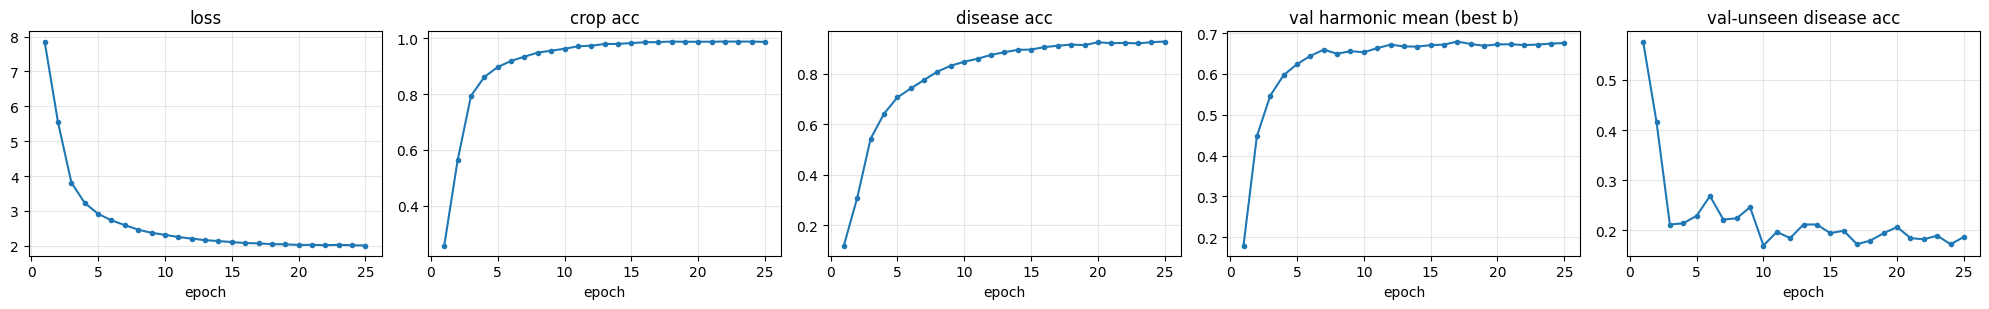

In [12]:
hist = pd.DataFrame(history)
panels = [('train_loss', 'loss'), ('train_crop_acc', 'crop acc'), ('train_disease_acc', 'disease acc')]
if CFG['run_mode'] == 'dev':
    panels += [('val_best_hm', 'val harmonic mean (best b)'), ('val_unseen_disease_acc', 'val-unseen disease acc')]
fig, axes = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.2))
for ax, (col, title) in zip(np.atleast_1d(axes), panels):
    ax.plot(hist['epoch'], hist[col], marker='o', ms=3)
    ax.set_title(title); ax.set_xlabel('epoch'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'training_curves.png'), dpi=150); plt.show()

## 12. Dev summary (dev mode only)
This saves the best epoch and bias. The final run reads them from `outputs/.../dev/summary.json`.

{
  "best_epoch": 17,
  "best_bias": 4.9360127449035645,
  "val_best_hm": 0.679489921991421,
  "val_seen_at_best": 0.7366771101951599,
  "val_unseen_at_best": 0.6305418610572815,
  "val_auc": 0.5923780390570639,
  "holdout_pairs": [
    "apple_healthy",
    "blackgram_powdery_mildew",
    "broccoli_alternaria_leaf_spot",
    "broccoli_ring_spot",
    "cauliflower_bacterial_spot",
    "cauliflower_black_rot",
    "cherry_spot",
    "citrus_black_spot",
    "cucumber_angular_leaf_spot",
    "paddy_bacterial_blight",
    "papaya_curl",
    "plum_aphis_spp",
    "sugarcane_smut",
    "tea_healthy",
    "tomato_mosaic_virus"
  ]
}


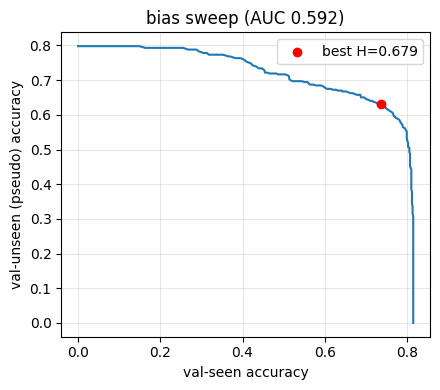

In [13]:
if CFG['run_mode'] == 'dev':
    best = torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)
    model.load_state_dict(best['model'])
    vs, vu = run_inference(model, val_seen_loader), run_inference(model, val_unseen_loader)
    sweep = bias_sweep(comp_scores(vs), vs['comp'], comp_scores(vu), vu['comp'])
    summary = dict(best_epoch=best['epoch'], best_bias=sweep['best_bias'], val_best_hm=sweep['best_hm'],
                   val_seen_at_best=sweep['best_seen'], val_unseen_at_best=sweep['best_novel'],
                   val_auc=sweep['auc'], holdout_pairs=[COMP_NAMES[c] for c in HOLDOUT], cfg=CFG)
    json.dump(summary, open(DEV_SUMMARY, 'w'), indent=2)
    print(json.dumps({k: v for k, v in summary.items() if k != 'cfg'}, indent=2))

    plt.figure(figsize=(4.5, 4))
    plt.plot(sweep['seen'], sweep['novel'], '-')
    plt.scatter([sweep['best_seen']], [sweep['best_novel']], c='r', zorder=3, label=f"best H={sweep['best_hm']:.3f}")
    plt.xlabel('val-seen accuracy'); plt.ylabel('val-unseen (pseudo) accuracy'); plt.legend()
    plt.title(f"bias sweep (AUC {sweep['auc']:.3f})"); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, 'val_bias_curve.png'), dpi=150); plt.show()

In [14]:
if CFG['run_mode'] != 'final':
    raise SystemExit('Dev run finished. Set run_mode="final" in the config cell and Run all again.')

SystemExit: Dev run finished. Set run_mode="final" in the config cell and Run all again.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## 13. Final test evaluation
The headline numbers use the bias $b$ picked on the dev validation set. The "oracle" row uses the best $b$ *on the test set itself*. It's only an upper bound for the discussion and is never the reported result.

In [ ]:
model.load_state_dict(torch.load(BEST_CKPT, map_location=DEVICE, weights_only=False)['model'])
ts = run_inference(model, make_loader(test_seen_df, train=False))
tu = run_inference(model, make_loader(test_unseen_df, train=False))
S_test, U_test = comp_scores(ts), comp_scores(tu)
DEV_BIAS = json.load(open(DEV_SUMMARY))['best_bias'] if os.path.exists(DEV_SUMMARY) else 0.0
test_sweep = bias_sweep(S_test, ts['comp'], U_test, tu['comp'])

def report(bias):
    s1, u1 = topk_acc(S_test, ts['comp'], 1, bias), topk_acc(U_test, tu['comp'], 1, bias)
    return {'bias': round(bias, 3), 'seen top-1': s1, 'seen top-5': topk_acc(S_test, ts['comp'], 5, bias),
            'unseen top-1': u1, 'unseen top-5': topk_acc(U_test, tu['comp'], 5, bias),
            'harmonic mean': harmonic_mean(s1, u1)}

results = pd.DataFrame({
    'b = 0 (no calibration)': report(0.0),
    'b from dev validation (REPORTED)': report(DEV_BIAS),
    'oracle b on test (upper bound)': report(test_sweep['best_bias']),
}).T
display(results.style.format({c: '{:.2%}' for c in results.columns if c != 'bias'}))
print(f"seen/unseen AUC: {test_sweep['auc']:.4f}")

plt.figure(figsize=(4.5, 4))
plt.plot(test_sweep['seen'], test_sweep['novel'], '-')
r = report(DEV_BIAS)
plt.scatter([r['seen top-1']], [r['unseen top-1']], c='r', zorder=3, label=f"dev b, H={r['harmonic mean']:.3f}")
plt.xlabel('test-seen top-1'); plt.ylabel('test-unseen top-1'); plt.legend(); plt.grid(alpha=.3)
plt.title(f"Baseline 2 bias sweep (AUC {test_sweep['auc']:.3f})"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'test_bias_curve.png'), dpi=150); plt.show()

## 14. DPD paper protocol, and where the model fails
The DPD paper (Chai et al., ACM MM 2025) evaluates crop accuracy, disease accuracy and joint crop+disease accuracy, where each head predicts on its own (plain argmax, no pair list, no bias). A pair counts as correct only if both heads are right. We report this too, so our numbers can be compared with the paper's Table 4. That table uses the full DPD dataset, not DPD-Small, so it's a reference point rather than a like-for-like comparison.

If crop accuracy stays high on unseen images while disease accuracy drops, the disease head is the weak link. The **shortcut rate** is the share of wrong disease predictions on unseen images that name a disease the *true crop* had in training. A high rate means the model guesses the disease from the crop instead of from the symptoms. That's entanglement, and the contrastive method is meant to fix it.

In [ ]:
def paper_protocol(out):
    pc, pdis = out['crop_lp'].argmax(1), out['dis_lp'].argmax(1)
    return {'crop acc': (pc == out['crop']).float().mean().item(),
            'disease acc': (pdis == out['disease']).float().mean().item(),
            'crop+disease acc': ((pc == out['crop']) & (pdis == out['disease'])).float().mean().item()}

head_table = pd.DataFrame({'test-seen': paper_protocol(ts), 'test-unseen': paper_protocol(tu)}).T
display(head_table.style.format('{:.2%}'))
PAPER_HM = harmonic_mean(head_table.at['test-seen', 'crop+disease acc'], head_table.at['test-unseen', 'crop+disease acc'])
print(f'paper-protocol harmonic mean: {PAPER_HM:.2%}  '
      '(paper Table 4, full DPD, ViT-B/16: seen 78.53%, unseen 2.69%, HM 5.20%)')

train_pairs = set(zip(fit_df['crop'], fit_df['disease']))
pred_dis = tu['dis_lp'].argmax(1)
wrong = pred_dis != tu['disease']
shortcut = [(int(c), int(d)) in train_pairs for c, d in zip(tu['crop'][wrong], pred_dis[wrong])]
SHORTCUT_RATE = float(np.mean(shortcut)) if shortcut else 0.0
print(f'unseen images with the wrong disease: {int(wrong.sum())}/{len(wrong)}')
print(f'shortcut rate (wrong disease is one the true crop had in training): {SHORTCUT_RATE:.2%}')

## 15. Confusion matrices (test-seen, with the dev bias)
The full 323-pair matrix is too dense to read pair by pair, so we also show the crop-level matrix and a table of the most-confused pairs. The full matrix is saved as CSV for the report.

In [ ]:
from sklearn.metrics import confusion_matrix
pred_seen = (S_test + DEV_BIAS * NOVEL_MASK.float()).argmax(1)
cm = confusion_matrix(ts['comp'].numpy(), pred_seen.numpy(), labels=list(range(NUM_COMPS)))
pd.DataFrame(cm, index=COMP_NAMES, columns=COMP_NAMES).to_csv(os.path.join(OUT_DIR, 'confusion_test_seen_pairs.csv'))

seen_ids = sorted(set(test_seen_df['comp']))
cm_seen = cm[np.ix_(seen_ids, seen_ids)].astype(float)
cm_norm = cm_seen / np.maximum(cm_seen.sum(1, keepdims=True), 1)
crop_cm = confusion_matrix(ts['crop'].numpy(), COMP_CROP[pred_seen].numpy(), labels=list(range(NUM_CROPS))).astype(float)
crop_norm = crop_cm / np.maximum(crop_cm.sum(1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
axes[0].imshow(cm_norm, cmap='viridis', vmin=0, vmax=1)
axes[0].set_title(f'test-seen confusion, {len(seen_ids)} seen pairs (row-normalised)')
axes[0].set_xlabel('predicted pair'); axes[0].set_ylabel('true pair')
im = axes[1].imshow(crop_norm, cmap='viridis', vmin=0, vmax=1)
axes[1].set_title('crop-level confusion (test-seen)')
axes[1].set_xticks(range(NUM_CROPS)); axes[1].set_xticklabels(CROP_NAMES, rotation=90, fontsize=5)
axes[1].set_yticks(range(NUM_CROPS)); axes[1].set_yticklabels(CROP_NAMES, fontsize=5)
fig.colorbar(im, ax=axes, shrink=.7)
plt.savefig(os.path.join(OUT_DIR, 'confusion_test_seen.png'), dpi=200, bbox_inches='tight'); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:15], off.shape))[0]
display(pd.DataFrame([dict(true=COMP_NAMES[i], predicted=COMP_NAMES[j], count=int(off[i, j]))
                      for i, j in top if off[i, j] > 0]))

## 16. Is the shared feature organised by crop or by disease?
We take the test images whose disease appears in an unseen pair (diseases that occur on several crops). A **silhouette score** measures how cleanly their features cluster by crop versus by disease. If the crop score is higher, the representation is organised around crop identity, which is why new crop + disease pairings are hard. The t-SNE plots show the same thing visually.

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE

feat = F.normalize(torch.cat([ts['feat'], tu['feat']]), dim=1).numpy()
crop_lab = torch.cat([ts['crop'], tu['crop']]).numpy()
dis_lab = torch.cat([ts['disease'], tu['disease']]).numpy()
focus = np.isin(dis_lab, comps.loc[sorted(UNSEEN_COMPS), 'disease'].values)
f, c, d = feat[focus], crop_lab[focus], dis_lab[focus]

def safe_silhouette(x, y):
    return float(silhouette_score(x, y, metric='cosine')) if 1 < len(set(y)) < len(y) else float('nan')

SIL_CROP, SIL_DIS = safe_silhouette(f, c), safe_silhouette(f, d)
print(f'{focus.sum()} images | silhouette by crop {SIL_CROP:.3f} | by disease {SIL_DIS:.3f}')

if len(f) > 5:
    emb = TSNE(n_components=2, perplexity=min(30, len(f) - 1), init='pca', random_state=CFG['seed']).fit_transform(f)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, lab, name in ((axes[0], c, 'crop'), (axes[1], d, 'disease')):
        ax.scatter(emb[:, 0], emb[:, 1], c=pd.factorize(lab)[0], cmap='tab20', s=6)
        ax.set_title(f'shared feature coloured by {name}'); ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'tsne_crop_vs_disease.png'), dpi=150); plt.show()

## 17. Save metrics and the feature bank for the UI
`feature_bank.npz` holds an L2-normalised feature for every training image. The UI uses it to show the training images that best match a query.

In [ ]:
bank = run_inference(model, make_loader(fit_df, train=False))
BANK_FEATS = F.normalize(bank['feat'], dim=1)
np.savez_compressed(os.path.join(OUT_DIR, 'feature_bank.npz'), feats=BANK_FEATS.numpy().astype(np.float16),
                    files=fit_df['file'].values, comp=bank['comp'].numpy(),
                    crop=bank['crop'].numpy(), disease=bank['disease'].numpy())

metrics = dict(model='Baseline 2: multi-task ResNet-50', epochs=EPOCHS, dev_bias=DEV_BIAS,
               results={k: v for k, v in results.to_dict(orient='index').items()},
               auc=test_sweep['auc'], heads=head_table.to_dict(orient='index'),
               paper_protocol_hm=PAPER_HM, shortcut_rate=SHORTCUT_RATE, silhouette_crop=SIL_CROP, silhouette_disease=SIL_DIS, cfg=CFG)
json.dump(metrics, open(os.path.join(OUT_DIR, 'metrics.json'), 'w'), indent=2)
print('saved to', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

## 18. Demo — identify one image
The UI flow: image in, top-5 crop + disease pairs out, plus the most similar training images.

In [ ]:
@torch.no_grad()
def identify(path, k=5, n_neighbours=5, bias=DEV_BIAS):
    model.eval()
    img = load_upright(path)
    lc, ld, feat = model(eval_tf(img)[None].to(DEVICE))
    s = F.log_softmax(lc.float(), 1).cpu()[0][COMP_CROP] + F.log_softmax(ld.float(), 1).cpu()[0][COMP_DIS]
    s = s + bias * NOVEL_MASK.float()
    probs = s.softmax(0)
    top = probs.topk(k)
    preds = [(COMP_NAMES[i], float(p)) for p, i in zip(top.values, top.indices)]
    sims = BANK_FEATS @ F.normalize(feat.float().cpu(), dim=1)[0]
    nn_idx = sims.topk(n_neighbours).indices.tolist()

    fig, axes = plt.subplots(1, n_neighbours + 1, figsize=(3 * (n_neighbours + 1), 3.4))
    axes[0].imshow(img); axes[0].set_title('query\n' + '\n'.join(f'{n} {p:.0%}' for n, p in preds[:3]), fontsize=7)
    for ax, i in zip(axes[1:], nn_idx):
        ax.imshow(Image.open(os.path.join(IMAGE_DIR, fit_df['file'].iloc[i])).convert('RGB'))
        ax.set_title(f"{COMP_NAMES[int(fit_df['comp'].iloc[i])]}\nsim {sims[i]:.2f}", fontsize=7)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout(); plt.show()
    return preds

sample = test_unseen_df.iloc[0]
print('true pair:', sample['comp_name'])
identify(os.path.join(IMAGE_DIR, sample['file']))